# Country Intelligence

Compare observed exporter and importer activity in the supplied extract. Numeric identifiers can represent countries, historical entries, or trade areas.

See the [release guide](../docs/TRADE_INTELLIGENCE_RELEASE.md) for the source and validation workflow.

In [1]:
from pathlib import Path
import sys

from IPython.display import Markdown, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "notebooks" / "notebook_support.py").is_file())
sys.path.insert(0, str(root / "notebooks"))
from notebook_support import BLUE, GOLD, TEAL, bar_chart, load_release, top

manifest, data = load_release('country_intelligence')
year = manifest["year"]
display(Markdown(f"**Dataset year:** {year}  |  **Release:** `{manifest['release_id']}`"))


**Dataset year:** 2024  |  **Release:** `ti-3349f6e0cb6dde75fe7d5323af71463748cad3232bc7bcb476c6ff6dcd8cd41b`

## Charts

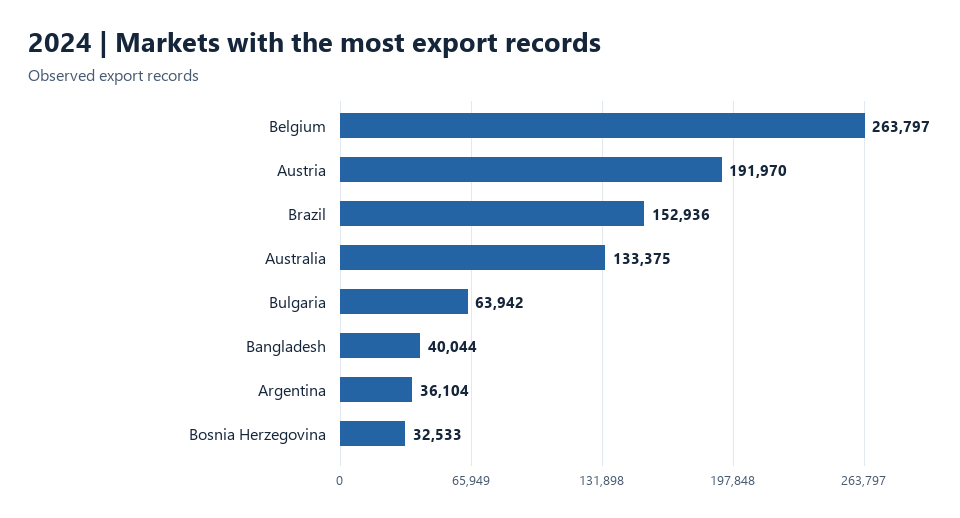

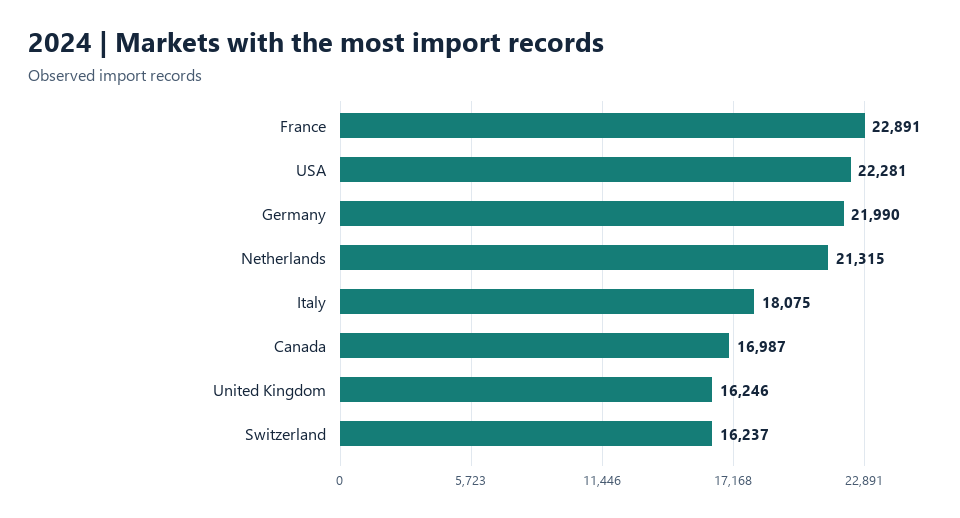

In [2]:
rows = data["records"]
exports = top(rows, "export_record_count", lambda r: r["code"])
imports = top(rows, "import_record_count", lambda r: r["code"])

display(bar_chart(f"{year} | Markets with the most export records",
                  "Observed export records", [(r["name"], r["export_record_count"]) for r in exports], BLUE))
display(bar_chart(f"{year} | Markets with the most import records",
                  "Observed import records", [(r["name"], r["import_record_count"]) for r in imports], TEAL))


## Analysis

In [3]:
outgoing = sum(r["export_record_count"] for r in rows)
incoming = sum(r["import_record_count"] for r in rows)
exporters = sum(r["export_record_count"] > 0 for r in rows)
importers = sum(r["import_record_count"] > 0 for r in rows)
idle = sum(r["export_record_count"] == r["import_record_count"] == 0 for r in rows)
assert outgoing == incoming == manifest["statistics"]["eligible_records"]
e, i = exports[0], imports[0]
display(Markdown(f'''
### What the charts show
- The release covers **{len(rows):,}** reference entries, with **{exporters}** observed exporters and **{importers}** observed importers. **{idle}** entries have zero records in both directions.
- **{e["name"]}** leads the extract by export record count, with **{e["export_record_count"]:,}** records across **{e["export_destinations"]}** destinations. **{i["name"]}** leads by import count, with **{i["import_record_count"]:,}** records from **{i["import_sources"]}** observed origins.
- Both perspectives reconcile to **{outgoing:,}** eligible records. The exporter and importer charts use separate scales. The smaller exporter pool reflects the extract's coverage and affects how the rankings should be read.
'''))



### What the charts show
- The release covers **238** reference entries, with **29** observed exporters and **226** observed importers. **12** entries have zero records in both directions.
- **Belgium** leads the extract by export record count, with **263,797** records across **221** destinations. **France** leads by import count, with **22,891** records from **29** observed origins.
- Both perspectives reconcile to **1,048,575** eligible records. The exporter and importer charts use separate scales. The smaller exporter pool reflects the extract's coverage and affects how the rankings should be read.


### Reading the results

The single-year export reached Excel's worksheet limit and has partial geographic coverage. Record counts measure observed keys in the extract. Currency, trade-value scale, quantity units and HS revision remain unverified. These charts use neither trade values nor quantities. Missing observations provide no evidence of market absence, and the extract cannot establish trends or future demand.
